# Polynomial Regression — From-Scratch Implementation with NumPy

---

## What will we learn in this notebook?

In this hands-on lesson we build a **Polynomial Regression** model completely **from scratch**, using **only NumPy**, and fit it to synthetically generated nonlinear data.

We will also write the **MSE** and **R²** evaluation metrics ourselves, as NumPy functions, so we can judge how good our model is.

> **Important constraint:** We do **not** use `scikit-learn`. Only `numpy`, and `matplotlib` for visualization.

## Section 1. Importing the Required Libraries

We only use two libraries:
- **NumPy** — for working with matrices and vectors (all the math happens here).
- **Matplotlib** — for plotting the results as charts.

In [1]:
# numpy - the main library for numerical computing (we import it as np for short)
import numpy as np

# matplotlib.pyplot - for drawing charts (we import it as plt for short)
import matplotlib.pyplot as plt

# We set a random "seed" so the random results are the same every time we run this
# This is needed for reproducibility
np.random.seed(42)

print("Libraries loaded successfully!")
print("NumPy version:", np.__version__)

Libraries loaded successfully!
NumPy version: 2.5.3


## Section 2. Writing Evaluation Metrics from Scratch (MSE and R²)

To know how well our model is performing, we need a **metric**.
We will write two of them ourselves — no `scikit-learn`.

### 2.1. MSE — Mean Squared Error

MSE takes the difference between each prediction (`y_pred`) and the true value (`y_true`),
squares it (to get rid of the negative sign and to penalize large errors more),
and takes the average.

$$ MSE = \frac{1}{m} \sum_{i=1}^{m} (y_i - \hat{y}_i)^2 $$

- $y_i$ — the true value
- $\hat{y}_i$ — the model's prediction
- $m$ — the number of samples (data points)

**Rule:** The smaller the MSE, the more accurate the model.

In [2]:
def mse(y_true, y_pred):
    """
    Mean Squared Error.
    y_true : the true values (numpy array)
    y_pred : the model's predictions (numpy array)
    """
    # Compute the (true - predicted) difference - this is the error at each point
    error = y_true - y_pred

    # Square each error (** 2 - the power operator)
    squared_error = error ** 2

    # Take the average of all the squared errors (np.mean - average)
    result = np.mean(squared_error)

    # Return the result
    return result


# Let's check it with a simple example
a = np.array([3.0, 5.0, 2.0])   # true values
b = np.array([2.5, 5.0, 4.0])   # predictions
print("MSE example result:", mse(a, b))

MSE example result: 1.4166666666666667


### 2.2. R² — Coefficient of Determination (R-squared)

R² shows what percentage of the variability in our data the model is able to explain.

$$ R^2 = 1 - \frac{SS_{res}}{SS_{tot}} $$

Where:
- $SS_{res} = \sum (y_i - \hat{y}_i)^2$ — the sum of the model's residual errors (residual sum of squares)
- $SS_{tot} = \sum (y_i - \bar{y})^2$ — the total variability (total sum of squares), $\bar{y}$ — the mean value

**Rule:** The closer R² is to 1, the better the model.
- R² = 1 → a perfect model
- R² = 0 → the model is no better than just predicting the mean

In [3]:
def r2_score(y_true, y_pred):
    """
    R-squared (coefficient of determination).
    y_true : the true values
    y_pred : the predictions
    """
    # The mean of the true values (the mean of y, over the whole line)
    y_mean = np.mean(y_true)

    # SS_res: the sum of squares of the model's residual errors
    ss_res = np.sum((y_true - y_pred) ** 2)

    # SS_tot: the sum of squares of the data's total deviation from the mean
    ss_tot = np.sum((y_true - y_mean) ** 2)

    # The R2 formula: 1 - (residual / total)
    result = 1 - (ss_res / ss_tot)

    return result


# Let's check it
print("R2 example result:", r2_score(a, b))

R2 example result: 0.08928571428571419


## Section 3. Polynomial Regression (on Synthetic Data)

### 3.1. Why polynomial?
Sometimes data is **not** well described by a straight line, but by a curve.
For example, if the relationship looks like this:

$$ y = 0.5x^3 - x^2 + 2x + noise $$

Here a linear model isn't enough. The solution is to **expand the input into powers**:

$$ \hat{y} = w_0 + w_1 x + w_2 x^2 + \dots + w_d x^d $$

We do this by building a **feature matrix**.

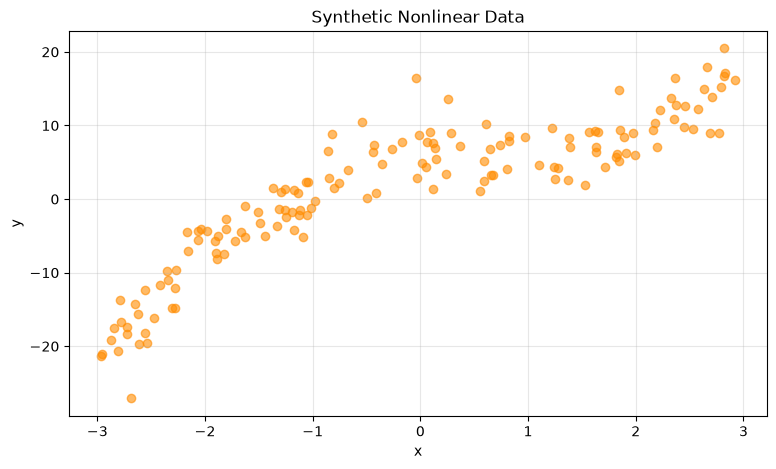

In [4]:
# --- Generating synthetic data ---
n_synth = 150

# x values: from -3 to 3
x_poly = np.random.uniform(-3, 3, n_synth)

# The true underlying curve: 0.5x^3 - x^2 + 2x + 5
y_poly_clean = 0.5 * x_poly**3 - x_poly**2 + 2 * x_poly + 5

# Add random noise
y_poly = y_poly_clean + np.random.normal(0, 3, n_synth)

# Let's take a look
plt.figure(figsize=(9, 5))
plt.scatter(x_poly, y_poly, color='darkorange', alpha=0.6)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Synthetic Nonlinear Data")
plt.grid(True, alpha=0.3)
plt.show()

### 3.2. Building the Polynomial Feature Matrix
For every `x` we build columns: `[1, x, x², ..., x^degree]`.
The first column (all 1s) is for the bias term.

In [5]:
def polynomial_features(x, degree):
    """
    Builds a polynomial feature matrix from the vector x.
    Result columns: [1, x, x^2, ..., x^degree]
    """
    # Empty list - we'll collect each degree's column here
    columns = []

    # For each power from 0 up to (and including) degree
    for d in range(degree + 1):
        # Raise x to the power d and add it as a column
        columns.append(x ** d)

    # Stack the columns side by side into a matrix
    # np.column_stack - turns vectors into the columns of a matrix
    X_matrix = np.column_stack(columns)

    return X_matrix


# Example: the shape of the matrix for degree 3
example = polynomial_features(x_poly, degree=3)
print("Feature matrix shape:", example.shape)   # (samples, degree+1)
print("First row:", np.round(example[0], 2))

Feature matrix shape: (150, 4)
First row: [ 1.   -0.75  0.57 -0.43]


### 3.3. Solving with a Closed-Form Solution (Normal Equation)
Instead of gradient descent, we solve polynomial regression with a **direct matrix formula**
(the Normal Equation) — from scratch, using only NumPy:

$$ \mathbf{w} = (X^T X)^{-1} X^T y $$

This formula computes the weights that minimize MSE in a single step.

In [6]:
def normal_equation(X, y):
    """
    Finds the weights (w) using the Normal Equation: w = (X^T X)^(-1) X^T y
    X : the feature matrix
    y : the true values
    """
    # X^T - the transpose of matrix X (.T)
    Xt = X.T

    # X^T X - a square matrix (@ - matrix multiplication)
    XtX = Xt @ X

    # (X^T X)^(-1) - the matrix inverse (np.linalg.inv)
    XtX_inv = np.linalg.inv(XtX)

    # X^T y - a vector
    Xty = Xt @ y

    # Final formula: w = (X^T X)^(-1) (X^T y)
    w = XtX_inv @ Xty

    return w


# --- Train/test split (for the synthetic data) ---
idx = np.random.permutation(n_synth)
x_poly, y_poly = x_poly[idx], y_poly[idx]
split_idx = int(0.8 * n_synth)

x_tr, x_te = x_poly[:split_idx], x_poly[split_idx:]
y_tr, y_te = y_poly[:split_idx], y_poly[split_idx:]

# Build the features for a degree-3 polynomial
degree = 3
X_tr_poly = polynomial_features(x_tr, degree)
X_te_poly = polynomial_features(x_te, degree)

# Solve for the weights
w_poly = normal_equation(X_tr_poly, y_tr)
print("Learned weights (w0..w3):", np.round(w_poly, 3))

Learned weights (w0..w3): [ 5.128  1.85  -0.944  0.528]


### 3.4. Evaluating the Polynomial Model

In [7]:
# Test predictions: multiply the matrix by the weights
y_te_pred = X_te_poly @ w_poly

# Evaluate using the metrics we wrote ourselves
poly_mse = mse(y_te, y_te_pred)
poly_r2 = r2_score(y_te, y_te_pred)

print("=== Polynomial Regression Results (TEST) ===")
print("Degree :", degree)
print("MSE    :", round(poly_mse, 3))
print("R2     :", round(poly_r2, 4))

=== Polynomial Regression Results (TEST) ===
Degree : 3
MSE    : 15.917
R2     : 0.8909


### 3.5. Visualizing the Model Curve

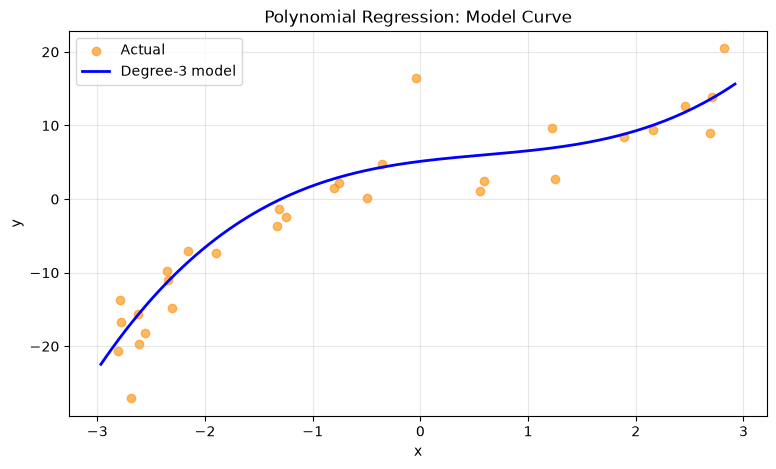

In [8]:
plt.figure(figsize=(9, 5))

# Test points
plt.scatter(x_te, y_te, color='darkorange', alpha=0.6, label="Actual")

# Sorted x values for a smooth curve
x_smooth = np.linspace(x_poly.min(), x_poly.max(), 200)
X_smooth = polynomial_features(x_smooth, degree)   # expand them too
y_smooth = X_smooth @ w_poly                       # model prediction

plt.plot(x_smooth, y_smooth, color='blue', linewidth=2, label=f"Degree-{degree} model")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Polynomial Regression: Model Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 3.6. Comparing Different Degrees (Underfitting and Overfitting)
Now let's compute R² for several degrees and see which one is best.
- **Too low a degree** → the model doesn't learn enough (underfitting).
- **Too high a degree** → the model starts memorizing the noise too (overfitting).

In [ ]:
# The list of degrees to try
degrees = [1, 2, 3, 5, 9]

print(f"{'Degree':>7} | {'Train R2':>10} | {'Test R2':>10}")
print("-" * 34)

for d in degrees:
    # Build the features
    Xtr = polynomial_features(x_tr, d)
    Xte = polynomial_features(x_te, d)

    # Solve for the weights
    w_d = normal_equation(Xtr, y_tr)

    # Compute the train and test R2
    r2_tr = r2_score(y_tr, Xtr @ w_d)
    r2_te = r2_score(y_te, Xte @ w_d)

    print(f"{d:>7} | {r2_tr:>10.4f} | {r2_te:>10.4f}")

**Observation:** Around degree 3 the model already fits the data well — matching the true cubic
relationship — with train and test R² close together. As the degree increases further (5, 9), train R²
keeps creeping up while the improvement in test R² becomes marginal, and the gap between the two slowly
widens. That widening gap is the hallmark of **overfitting**: the extra flexibility mostly ends up fitting
noise rather than real signal. (With more noise or a smaller dataset, this effect shows up even more
clearly — try it yourself in the exercise below!)

### TODO (practice on your own) ⭐⭐
1. Change `degree` to `2` and `7`, and see how the model curve changes.
2. Change the synthetic data law (e.g. `y = x^2 + noise`) and retrain the model.
3. Increase the noise spread and observe how much the high-degree models "break down".

## Conclusion — What We Learned

In this notebook, using **only NumPy**, we:

1. Wrote the **MSE** and **R²** metrics from scratch as functions.
2. Built **Polynomial Regression** on synthetic data using the Normal Equation (a direct matrix formula).
3. Explored **underfitting** and **overfitting** by comparing different polynomial degrees.

**Key ideas:**
- Polynomial features let a linear model fit nonlinear data by expanding the input into powers of x.
- The Normal Equation computes the optimal weights in a single step — no iterative training needed.
- Metrics (MSE, R²) help evaluate a model objectively.
- Too low a degree underfits the data; too high a degree overfits it — the best degree matches the true complexity of the data.

---